<a href="https://colab.research.google.com/github/JMTolbert2005/Kmeansunsupervisedemotions/blob/main/MLSN_Team_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.cluster as kmeans

# Paste your actual sharing link here
url = 'https://drive.google.com/file/d/1yI-gzt1m7LVNqQ0f12111kcG8tA7j17z/view?usp=sharing'

# Extract the file ID from the URL
file_id = url.split('/d/')[1].split('/')[0]

# Create a direct download link
download_url = f'https://drive.google.com/uc?id={file_id}'

# Read the CSV
df = pd.read_csv(download_url)
df.head()



,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [ ]:
# Demo 1 - Dataframe Basics Post Loading

#Load your dataset and check the head() and tail() function to determine general layout
SpotifyDF = df
SpotifyDF.head()



,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [ ]:
# Use functions such as .columns and len() to get more accurate numerical statistics on your data
SpotifyDFname = df.columns
print(SpotifyDFname)

SpotifyDFlen = len(SpotifyDF)
print(SpotifyDFlen)

Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='object')
114000


In [ ]:
# Begin The cleaning process by checking for NA rows

SpotifyNA = SpotifyDF.isna().sum()
print("The summary of NAs is as follows:"
, SpotifyNA)


The summary of NAs is as follows: Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [ ]:
#Repeat above for "" and 0 rows

SpotifyZero = SpotifyDF.isin([0]).sum()
print("The summary of 0s is as follows:"
, SpotifyZero)

SpotifyEmpty = SpotifyDF.isin(['']).sum()
print("The summary of ""s is as follows:"
, SpotifyEmpty)


The summary of 0s is as follows: Unnamed: 0               1
track_id                 0
artists                  0
album_name               0
track_name               0
popularity           16020
duration_ms              1
explicit            104253
danceability           157
energy                   1
key                  13061
loudness                 0
mode                 41319
speechiness            157
acousticness            39
instrumentalness     38763
liveness                 2
valence                176
tempo                  157
time_signature         163
track_genre              0
dtype: int64
The summary of s is as follows: Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liv

In [ ]:
#Drop all NAs and Duplicates
cleaned_df = SpotifyDF.dropna()
cleaned_df = cleaned_df.drop_duplicates()
cleaned_df = cleaned_df.drop(columns=["Unnamed: 0"])



In [ ]:
len(cleaned_df)

113999

In [ ]:
# Demo 3 - Recognize how when just looking at the Track name, duration_ms, and artist the duration sticks out like a sore thumb

Demo3DF = cleaned_df[['track_name', 'duration_ms', 'artists']]
Demo3DF.head(n=5)

,track_name,duration_ms,artists
0,Comedy,230666,Gen Hoshino
1,Ghost - Acoustic,149610,Ben Woodward
2,To Begin Again,210826,Ingrid Michaelson;ZAYN
3,Can't Help Falling In Love,201933,Kina Grannis
4,Hold On,198853,Chord Overstreet


In [ ]:
# Demo 3 Cont. - To Remedy this issue we will convert the ms (Miliseconds) to seconds using simple division and then rename the column

# Rename column to fit the future updated scale
Demo3DF = Demo3DF.rename(columns={'duration_ms': 'duration_M'})

#Divide by 1000 for proper scale
Demo3DF['duration_M'] = Demo3DF['duration_M'] / 60000

Demo3DF.head(n=5)

,track_name,duration_M,artists
0,Comedy,3.844433,Gen Hoshino
1,Ghost - Acoustic,2.493500,Ben Woodward
2,To Begin Again,3.513767,Ingrid Michaelson;ZAYN
3,Can't Help Falling In Love,3.365550,Kina Grannis
4,Hold On,3.314217,Chord Overstreet


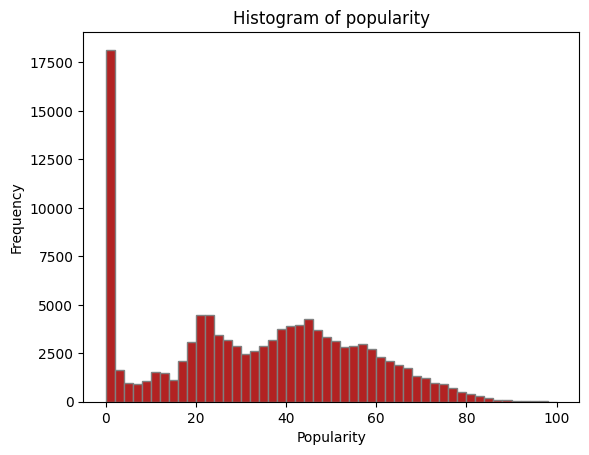

In [ ]:
#Histogram of popularity

import numpy as np
import matplotlib.pyplot as plt

plt.hist(cleaned_df['popularity'], bins=50, color= 'firebrick', edgecolor='grey')
plt.title('Histogram of popularity')
plt.xlabel('Popularity')
plt.ylabel('Frequency')
plt.show()

In [ ]:
#Remove low popularity songs



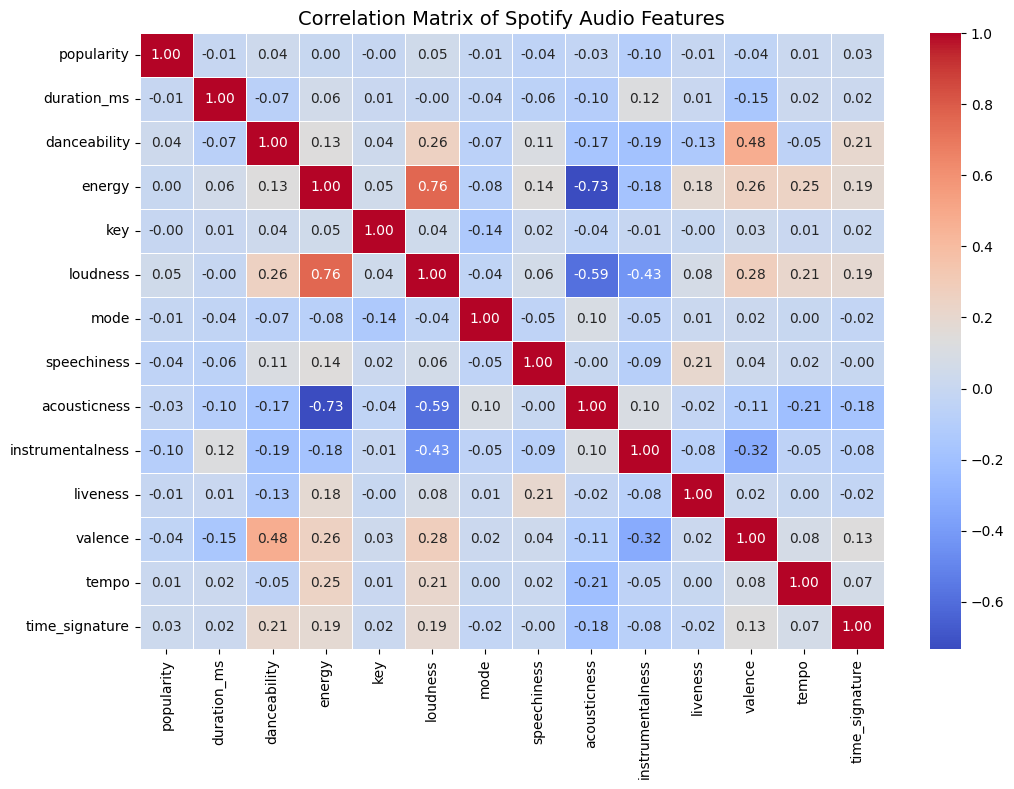

In [ ]:
numeric_cols = cleaned_df.select_dtypes(include=['number'])

corr_matrix = numeric_cols.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Spotify Audio Features", fontsize=14)
plt.show()

In [ ]:
#Defined Functional Stat tracker.
def stat_checker():

  stat = input("Enter a column name to check: ")
  x = int(input("Enter a threshold amount:"))


  rowPop = len(cleaned_df[cleaned_df[stat]>= x])
  result = rowPop

  print(f"There are {result} songs with a '{stat}' score >= {x} and {113999 - result} below score < {x}")

stat_checker()

KeyboardInterrupt: Interrupted by user

In [ ]:
# Begin Culling Data based on threshold
# Set a limit of popularity at atleast 1

cleaned_dfpop = cleaned_df[cleaned_df['popularity'] >  1]

#Set limit so all tracks must be longer than 45 seconds but shorter than 15 minutes
cleaned_dfms = cleaned_dfpop[cleaned_dfpop['duration_ms'] >  45000]
cleaned_dfms = cleaned_dfms[cleaned_dfms['duration_ms'] < 900000 ]

cleaned_dfms = cleaned_dfms.drop(columns=["time_signature","key", "explicit"])

SpotifyDFname2 = cleaned_dfms.columns
print(SpotifyDFname2)

len(cleaned_dfms)


In [ ]:
def stat_checker2():

  stat = input("Enter a column name to check in cleaned_dfms: ")
  x = int(input("Enter a threshold amount:"))


  rowPop = len(cleaned_dfms[cleaned_dfms[stat]>= x])
  result = rowPop

  print(f"There are {result} songs in cleaned_dfms with a '{stat}' score >= {x} and {len(cleaned_dfms) - result} below score < {x}")


stat_checker2()


In [ ]:
lowpopularity = cleaned_df.sort_values(by='popularity', ascending = False)
lowpopularity2 = lowpopularity[['popularity', 'track_name', 'album_name', 'artists' ]]
lowpopularity2.head(n=50)

,popularity,track_name,album_name,artists
20001,100,Unholy (feat. Kim Petras),Unholy (feat. Kim Petras),Sam Smith;Kim Petras
81051,100,Unholy (feat. Kim Petras),Unholy (feat. Kim Petras),Sam Smith;Kim Petras
51664,99,"Quevedo: Bzrp Music Sessions, Vol. 52","Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo
88410,98,La Bachata,La Bachata,Manuel Turizo
30003,98,I'm Good (Blue),I'm Good (Blue),David Guetta;Bebe Rexha
68303,98,La Bachata,La Bachata,Manuel Turizo
89411,98,La Bachata,La Bachata,Manuel Turizo
81210,98,I'm Good (Blue),I'm Good (Blue),David Guetta;Bebe Rexha
67356,98,La Bachata,La Bachata,Manuel Turizo
20008,98,I'm Good (Blue),I'm Good (Blue),David Guetta;Bebe Rexha


In [ ]:
#Remove Duplicates of track on the basis of track name and artist

cleaned_dfdup = cleaned_dfms.drop_duplicates(subset=['track_name','artists']).copy()

cleaned_dfdup.head(n=50)
len(cleaned_dfdup)

NameError: name 'cleaned_dfms' is not defined

In [ ]:
# Make Purely Function and test dataframe
df_test = cleaned_dfdup[['valence', 'energy',]]

print(df_test.head())

NameError: name 'cleaned_dfdup' is not defined

In [ ]:
def songsbyvalUuedf_test(df_test, minval, maxval, minenergy, maxenergy):

  filtered_dfresult = df_test[
      (df_test['valence'] >= minval) & (df_test['valence'] <= maxval) &
      (df_test['energy'] >= minenergy) & (df_test['energy'] <= maxenergy)
    ]

  return print(filtered_dfresult.head(n=10))

# Example usage (replace with your desired values)

songsbyvalUuedf_test(df_test, 0.4, 0.6, 0.85, 1)

In [ ]:
import sklearn.cluster as kmeans


In [ ]:
SpotifyDFname22 = cleaned_dfdup.columns
print(SpotifyDFname22)

In [ ]:
from sklearn.model_selection import train_test_split
est_df, train_df  = train_test_split(cleaned_dfms, test_size=0.2, random_state=67)

In [ ]:
from sklearn.cluster import KMeans

#Begin Clustering and labeling with KMeans
kmeans_model_test = KMeans(n_clusters=13, random_state = 0, n_init = "auto")
kmeans_model_test.fit(df_test)

Test_results0 = kmeans_model_test.labels_
Test_centers = kmeans_model_test.cluster_centers_

print(Test_results0)
print(Test_centers)

plt.figure(figsize=(10, 6))
plt.scatter(df_test['valence'], df_test['energy'], c=kmeans_model_test.labels_, cmap = 'rainbow', s=50, alpha = 0.5)
plt.scatter(kmeans_model_test.cluster_centers_[:, 0], kmeans_model_test.cluster_centers_[:, 1], c='white', marker='X', s=200, label='Centroids')
plt.title('K-Means Clustering of Audio Features')
plt.xlabel('Valence')
plt.ylabel('Energy')
plt.show()



plt.figure(figsize=(10,6))


In [ ]:
from sklearn.decomposition import PCA

PCADFTEST = cleaned_dfdup[['valence','energy','popularity','danceability','loudness','mode','speechiness','acousticness','instrumentalness','liveness','tempo']]

pca = PCA(n_components =2)
df_test_pca = pca.fit_transform(PCADFTEST)

df_test_pca = pd.DataFrame(df_test_pca, columns = ['PC1', 'PC2'])

print(df_test_pca.head())

In [ ]:
# Attempt PCA After Kmeans
from sklearn.cluster import KMeans

#Begin Clustering and labeling with KMeans
kmeans_model_testPCA = KMeans(n_clusters=13, random_state = 0, n_init = "auto")
kmeans_model_testPCA.fit(PCADFTEST)

Test_results = kmeans_model_testPCA.labels_
Test_centers = kmeans_model_testPCA.cluster_centers_

print(Test_results)
print(Test_centers)

pca = PCA(n_components =2)
df_test_pca = pca.fit_transform(PCADFTEST)

df_test_pca = pd.DataFrame(df_test_pca, columns = ['PC1', 'PC2'])

print(df_test_pca.head())


In [ ]:
from sklearn.decomposition import PCA

PCADFTEST = cleaned_dfdup[['valence','energy','popularity','danceability','loudness','mode','speechiness','acousticness','instrumentalness','liveness','tempo', 'duration_ms']]

pca = PCA(n_components =2)
df_test_pca = pca.fit_transform(PCADFTEST)

df_test_pca = pd.DataFrame(df_test_pca, columns = ['PC1', 'PC2'])

print(df_test_pca.head())

In [ ]:
from sklearn.cluster import KMeans
kmeans_model_test = KMeans(n_clusters=13, random_state = 0, n_init = "auto")
kmeans_model_test.fit(df_test_pca)

Test_results = kmeans_model_test.labels_
Test_centers = kmeans_model_test.cluster_centers_

print(Test_results)
print(Test_centers)

plt.figure(figsize=(10, 6))
plt.scatter(df_test_pca['PC1'], df_test_pca['PC2'], c=kmeans_model_test.labels_, cmap = 'rainbow', s=50, alpha = 0.5)
plt.scatter(kmeans_model_test.cluster_centers_[:, 0], kmeans_model_test.cluster_centers_[:, 1], c='white', marker='X', s=200, label='Centroids')
plt.title('K-Means Clustering of Audio Features')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()



plt.figure(figsize=(10,6))

In [ ]:
from sklearn.decomposition import PCA

PCADFTEST2 = cleaned_dfdup[['valence','energy','popularity','danceability','loudness','mode','speechiness','acousticness','instrumentalness','liveness','tempo']]

pca = PCA(n_components =2)
df_test_pca2 = pca.fit_transform(PCADFTEST2)

df_test_pca2  = pd.DataFrame(df_test_pca2, columns = ['PC1', 'PC2'])

print(df_test_pca2.head())

In [ ]:
# Attempt PCA without duration_ms

kmeans_model_test = KMeans(n_clusters=13, random_state = 0, n_init = "auto")
kmeans_model_test.fit(df_test_pca2)

Test_results3 = kmeans_model_test.labels_
Test_centers = kmeans_model_test.cluster_centers_

print(Test_results3)
print(Test_centers)

plt.figure(figsize=(10, 6))
plt.scatter(df_test_pca2['PC1'], df_test_pca2['PC2'], c=kmeans_model_test.labels_, cmap = 'rainbow', s=50, alpha = 0.5)
plt.scatter(kmeans_model_test.cluster_centers_[:, 0], kmeans_model_test.cluster_centers_[:, 1], c='white', marker='X', s=200, label='Centroids')
plt.title('K-Means Clustering of Audio Features')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()



plt.figure(figsize=(10,6))

In [ ]:
from sklearn.decomposition import PCA

PCADFTEST3 = cleaned_dfdup[['valence','energy','danceability','loudness','mode','speechiness','acousticness','instrumentalness','liveness','tempo']]

pca = PCA(n_components =2)
df_test_pca3 = pca.fit_transform(PCADFTEST3)

df_test_pca3  = pd.DataFrame(df_test_pca3, columns = ['PC1', 'PC2'])

In [ ]:
# Without Duration & population
kmeans_model_test = KMeans(n_clusters=13, random_state = 0, n_init = "auto")
kmeans_model_test.fit(df_test_pca3)

Test_results2 = kmeans_model_test.labels_
Test_centers2 = kmeans_model_test.cluster_centers_

print(Test_results2)
print(Test_centers2)

plt.figure(figsize=(10, 6))
plt.scatter(df_test_pca3['PC1'], df_test_pca3['PC2'], c=kmeans_model_test.labels_, cmap = 'rainbow', s=50, alpha = 0.5)
plt.scatter(kmeans_model_test.cluster_centers_[:, 0], kmeans_model_test.cluster_centers_[:, 1], c='white', marker='X', s=200, label='Centroids')
plt.title('K-Means Clustering of Audio Features')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()


In [ ]:

cleaned_dfdup['KmeansResult'] = Test_results0
cleaned_dfdup['PCAKMeansResultsNoPop'] = Test_results2
cleaned_dfdup.head(n=10)

In [ ]:
import pandas as pd

def get_songs_by_kmeans_label(cleaned_dfdup, PCAkmeans_label):

    filtered_songs = cleaned_dfdup[cleaned_dfdup['PCAKMeansResultsNoPop'] == PCAkmeans_label]

    if len(filtered_songs) > 0:
        # Select specific columns and take a random sample of up to 10 songs
        return filtered_songs[['artists', 'track_name', 'valence', 'energy', 'PCAKMeansResultsNoPop']].sample(n=min(20, len(filtered_songs)))
    else:
        return pd.DataFrame()

In [ ]:
get_songs_by_kmeans_label(cleaned_dfdup, 12)

In [ ]:

# Create Function to assign emotion to each category
def emotion_assign(row):
    kmeans_label = row['KmeansResult']

    if kmeans_label == 0:
        return 'sad'
    elif kmeans_label == 1:
        return 'Joyful'
    elif kmeans_label == 2:
        return 'Relaxed'
    elif kmeans_label == 3:
        return 'Upset'
    elif kmeans_label == 4:
        return 'Energetic'
    elif kmeans_label == 5:
        return 'Satisfied'
    elif kmeans_label == 6:
        return 'Angry'
    elif kmeans_label == 7:
        return 'Mellow'
    elif kmeans_label == 8:
        return 'Calm'
    elif kmeans_label == 9:
        return 'Excited'
    elif kmeans_label == 10:
        return 'Sulking'
    elif kmeans_label == 11:
        return 'Happy'
    elif kmeans_label == 12:
        return 'Suprised'
    else:
        return 'Unknown Emotion' # Fallback for unexpected labels

cleaned_dfdup['Emotion'] = cleaned_dfdup.apply(emotion_assign, axis=1)
cleaned_dfdup.head(n=10)

In [ ]:


# Create Function to assign emotion to each category
def emotion_assign(row):
    # Get the KmeansResult value for the current row
    PCAkmeans_label = row['PCAKMeansResultsNoPop']

    if PCAkmeans_label == 0:
        return 'Mellow/Laid-back'
    elif PCAkmeans_label == 1:
        return 'Dance'
    elif PCAkmeans_label == 2:
        return 'Happy'
    elif PCAkmeans_label == 3:
        return 'Excited/Commanding'
    elif PCAkmeans_label == 4:
        return 'Suprised/Shocked'
    elif PCAkmeans_label == 5:
        return 'Upset'
    elif PCAkmeans_label == 6:
        return 'White Noise/ Sleep'
    elif PCAkmeans_label == 7:
        return 'Groovy (?)'
    elif PCAkmeans_label == 8:
        return 'Thrilling (?)'
    elif PCAkmeans_label == 9:
        return 'Rockin (?)'
    elif PCAkmeans_label == 10:
        return 'Dreamy (?)'
    elif PCAkmeans_label == 11:
        return 'Inspriing (?)'
    elif PCAkmeans_label == 12:
        return 'Empowering  (?)'
    else:
        return 'Unknown Emotion' # Fallback for unexpected labels

cleaned_dfdup['PCAEmotion'] = cleaned_dfdup.apply(emotion_assign, axis=1)

cleaned_dfdup.head(n=10)